## Lecture 5

### Sharpening hint

```
original - (original median, max or mean) = detail
original + alpha * detail = sharpened image
```

### Bonus: Non-local means de-noising

key: "use [multiple] patches in image with similiar neighborhoods to average out the noise"

nonlinear filter - output not a linear combination of inputs and doesn't follow principles of superposition and homogeneity (F(a*x) = a*F(x)):


```
F(a*x1 + b*x2) != a*F(x1) + b*F(x2)
```

Behavior can't be modeled with mathematical convolution or a static impulse response coefficient.

Common types of nonlinear filtering techniques:
1. Median filters
2. Weighted median filters
3. Alpha-trimmed mean filter
4. Morphological filters (min and max filters): process signals or images based on structural geometry and shape. Used for object extraction, image enhancement
5. Order-statistic nonlinear filters

Additional filters:
* bilateral filter
* anisotropic diffusion (Perona-Malik)
* particle filters

General noise model

- challenging due to many sources and types of noise
- focusing on modeling a specific case is more effective
- consider noise a random variable with a probability density function (PDF) describing its behavior

### Nonlinear filter advantages and challenges

#### advantages over linear
* robust to noise
* edge preservation
* signal restoration - capable of reconstructing modified nonlinearly
* adaptability - some filters can adapt to local characterstics

#### challenges
* more complex
* computationally intensive
* parameter selection is difficult, needs expert or trial-error

### Linear vs Nonlinear uses

#### Linear filters
* blur edges and other details
* poor performance with nonGaussian noise
* result from Gaussian image and noise assumptions
* real images are not Gaussian

#### Nonlinear filters
* preserve edges
* effective impulsive noise removal
* result from nonGaussian image and noise assumptions
* difficult to design
* robustness to certain noise and effectively remove without blurring
* (some filters are) adaptable to local characteristics

### Image filtering methods

#### spatial domain
* represents light intensity at locations in space. Modify image by f and replace pixel value with function T (linear, nonlinear) of the local neighborhood pixels
* can clean salt and pepper, Gaussian, and speckled noise
#### frequency domain
* represents amplitudes across spectrum
* Uses Fourier Transform
* periodic noise requires frequency domain filtering due to global effect
* f(x,y) -> transform T(u,v) -> operation R[T(u,v)] -> Inverse transform -> g(x,y) where f(x,y) and g(x,y) are in the spatial domain

### Approaches

* spatial domain operations:
  - (single) point processing
  - mask/kernel-based (region of samples)
  
### Spatial filtering process for Restoration When There is Only Noise

```
g(x,y) = f(x,y) + n(x,y)
```

For a 3x3

```
e_processed = v*e + r*a + s*b + t*c + u*d + w*f + x*g + y*h + z*i
```

### Problem with Linear filter (averaging)

* blur edges and details
* not effective for impulse noise (salt and pepper)

Solution:
Order-statistics filters: take median value instead of average or weighted average of pixels in window

### Smoothing filters or masks based filters

* response is determined by ordering pixels contained in the image area covered by mask
  * median filtering
    * median of neighbors replaces gray level of each pixel
    * good at denoising (salt-and-pepper/impulse noise)
  * min: set pixel to neighborhood minimum
  * max: set pixel to neighborhood maximum

### Median filter: how it works

Usually impulse noise is isolated and has a high magnitude, so rarely will it be the medium.

### Median Filter Properties

```
median(f1 + f2) != median(f1) + median(f2)	# works for linear filters
median(cf) = c * median(f)
median(c + f) = c + median(f)
```

"The filter selects a sample from the window that does not average"
* no new gray values created, edge preserved, spike removed

### Median Filter: Optimization property

* sorting needs O(N^2) comparisons
* minimize the sum of absolute differences:

```
epsilon(g) = sum from k=1 to N abs(f_k - g)
```

### Median Filter: disadvantages

* Destroys fine details such as lines and corners
* tendency to incorporate noise spike into edge rather than filter
* expensive and complex to compute
* reduce impulsive noise but may not do as well as Gaussian or speckle noise and perform poorly in the presence of sing-dependent noise.

### Adaptive Median Filter (AMF)

#### 2 level

```
level a:
  a1 = zmed - zmin
  a2 = zmed - zmax
  if a1 > 0 and a2 < 0:
    go to b
  elif window size <= smax
    repeat a
  else
    output zxy
level b:
  b1 = zxy - zmin
  b2 = zxy - zmax
  if b1 > 0 and b2 < 0
    output zxy
  else
    output zmed
```

### AMF

* preserves sharpness and details
* 3 goals: remove impulse noise, provide smoothing of other noise, reduce distortions

### Weighted Median Filters

1. align weights with pixels by position
2. sum weights, divide by 2
3. order weights, summing weights for repeated values and calculate running sum.
4. find running sum that reaches value found in 2.

For negative weights, sign and magnitude are applied separately. negative filters act like high pass filters and can detect eddges

### Alpha-trimmed mean filters

* combines mean and median filters by sorting values in the window, throwing away extremes and averaging the rest
* use with mixed signal noise, such as gaussian and salt and pepper

### Sharpening filters (high pass)

purpose: highlight fine detail or enhance blurred details
basic highpass spatial filter:
* sum of mask coefficients is 0
* visual effect: enhanced edges on a dark background
* mask has positive and negative weights
* 1st and 2nd derivatives

```
eq: F + alpha(F - F * H) where F = image, F * H = blurred image
F - - F * H = F - F * H
F + alpha * detail = F + alpha(F - F*H)
```

### Adaptive Local Noise

```
mu1(x,y) = {mean, median, trimmed-mean}
f(x,y) - mu_l(x,y) + (sigma_l ** 2(x,y) - sigma_n ** 2(x,y)) / (sigma_l ** 2(x,y)) * (g(x,y) - mu_l(x,y))
```

### Unsharp masking and high-boost filters

unsharp masking:
* to generate mask, subtract blurred version of image from itself
* add the mask to the original

highboost:
* k > 1
* application: input image is very dark

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import inspect
import functools
import matplotlib.pyplot as plt

o241 = cv2.imread(f'/content/sample_data/2.4.1._original.jpg', cv2.IMREAD_GRAYSCALE)
o4461 = cv2.imread(f'/content/sample_data/4.46.1._original.jpg', cv2.IMREAD_GRAYSCALE)

blerg = cv2.cvtColor(cv2.imread(f'/content/sample_data/blerg.png',
                                cv2.IMREAD_COLOR),
                     cv2.COLOR_BGR2RGB)


In [ ]:
# Color spaces
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

class ColorSpaces:
  """Uses algorithms described on http://brucelindbloom.com/"""

  def __init__(self):
    # from rgb
    self.to_yiq = np.array([
      [0.299, 0.587, 0.114],
      [0.596, -0.274, -0.322],
      [0.212, -0.523, 0.312]
    ])
    # from rgb
    self.to_yuv = np.array([
      [0.299, 0.587, 0.114],
      [-0.14713, -0.28886, 0.436],
      [0.615, -0.51499, -0.10001]
    ])
    # from rgb
    self.to_xyz = np.array([
      [0.49, 0.31, 0.21],
      [0.18, 0.81, 0.01],
      [0.00, 0.01, 0.99]
    ])
    # from xyz
    self.to_rgb = np.array([
      [2.36, -0.89, -0.47],
      [-0.52, 1.42, 0.09],
      [0.01, -0.01, 1.01]
    ])
    # Note: I asked Mistral for a typical reference value for CIE L*a*b*
    self.white = np.array([0.9505, 1.0000, 1.0889])
    self.gamma = 2.2
    self.kappa = 903.3
    self.epsilon = 0.008856
    self.M = 255


  def rgb2yuv(self, img):
    return (img / 255) @ self.to_yuv.T

  def yuv2rgb(self, img):
    inv = np.linalg.inv(self.to_yuv)
    return (np.clip(img @ inv.T, 0, 1) * 255).astype(np.uint8)

  def rgb2yiq(self, img):
    return (img / 255) @ self.to_yiq.T

  def yiq2rgb(self, img):
    inv = np.linalg.inv(self.to_yiq)
    return (np.clip(img @ inv.T, 0, 1) * 255).astype(np.uint8)

  def rgb2xyz(self, img):
    return ((img / 255) ** self.gamma) @ self.to_xyz.T

  def xyz2rgb(self, img):
    img = np.nan_to_num(img, nan=0.0)
    clipped_img = np.clip(img @ self.to_rgb.T, 0, 1)
    return (clipped_img ** (1/self.gamma) * 255).astype(np.uint8)

  def rgb2hsv(self, img):
    img = img / 255.0
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    vmin = np.min([r, g, b], axis=0)
    vmax = np.max([r, g, b], axis=0)
    v = vmax
    s = np.divide(vmax - vmin, vmax, out = np.zeros_like(vmax, dtype = np.float64),
                  where = vmax != 0)
    condlist = [r == vmax, g == vmax, b == vmax]
    diff = vmax - vmin
    choicelist = [60 * np.divide(g - b, diff,
                                 out = np.zeros_like(diff, dtype=np.float64),
                                 where = diff != 0),
                  60 * (2 + np.divide(b - r, diff,
                                      out = np.zeros_like(diff, dtype=np.float64),
                                      where = diff != 0)),
                  60 * (4 + np.divide(r - g, diff,
                                      out = np.zeros_like(diff, dtype=np.float64),
                                      where = diff != 0))]
    h = np.select(condlist, choicelist, np.nan)
    h = np.where(h < 0, h + 360, h)
    return np.stack([h, s, v], axis = 2)

  def hsv2rgb(self, img):
    h, s, v = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    c = s * v
    m = v - c
    new_h = np.where(h >= 300, (h - 360) / 60, h / 60)

    condlist = [(new_h >= -1) & (new_h < 1),
                (new_h >= 1) & (new_h < 3),
                (new_h >= 3) & (new_h < 5)]

    r_choices = [v,
                 np.where(new_h - 2 < 0, m - (new_h - 2) * c, m),
                 np.where(new_h - 4 < 0, m,  m + (new_h - 4) * c)]
    r = np.select(condlist, r_choices, np.nan)

    g_choices = [np.where(new_h < 0, m,  m + new_h * c),
                 v,
                 np.where(new_h - 4 < 0, m - (new_h - 4) * c, m)]
    g = np.select(condlist, g_choices, np.nan)

    b_choices = [np.where(new_h < 0, m - new_h * c, m),
                 np.where(new_h - 2 < 0, m,  m + (new_h - 2) * c),
                 v]
    b = np.select(condlist, b_choices, np.nan)
    return np.stack([np.clip(r, 0, 1) * 255,
                      np.clip(g, 0, 1) * 255,
                      np.clip(b, 0, 1) * 255
                    ], axis=2).astype(np.uint8)

  def xyz2lab(self, img, white = None):
    if not white:
      white = self.white

    def f(r):
      return np.where(r > self.epsilon, np.cbrt(r), (self.kappa * r + 16)/116)

    xn, yn, zn = white[0], white[1], white[2]
    x, y, z = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    xr = x / xn
    yr = y / yn
    zr = z / zn
    L = 116 * f(yr) - 16
    a = 500 * (f(xr) - f(yr))
    b = 200 * (f(yr) - f(zr))
    return np.stack([L, a, b], axis = 2)

  def lab2xyz(self, img, white = None):
    if white is None:
      white = self.white

    xn, yn, zn = white[0], white[1], white[2]
    L, a, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]

    fy = (L + 16) / 116
    fz = fy - b / 200
    fx = a / 500 + fy

    xr = np.where(fx ** 3 > self.epsilon, fx ** 3, (116 * fx - 16) / self.kappa)
    yr = np.where(L > self.kappa * self.epsilon, ((L + 16)/ 116) ** 3,
                  L / self.kappa)
    zr = np.where(fz ** 3 > self.epsilon, fz ** 3, (116 * fz - 16) / self.kappa)
    return np.stack([xr * xn, yr * yn, zr * zn], axis = 2)

  def xyz2luv(self, img, white = None):
    if white is None:
      white = self.white

    xn, yn, zn = white[0], white[1], white[2]
    x, y, z = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    yr = y / yn

    d = x + 15 * y + 3 * z
    dn = xn + 15 * yn + 3 * zn
    u_ = np.divide(4 * x, d, out = np.zeros_like(d, dtype = np.float64),
                   where = d != 0)
    v_ = np.divide(9 * y, d, out = np.zeros_like(d, dtype = np.float64),
                   where = d != 0)
    ur = np.divide(4 * xn, dn, out = np.zeros_like(dn, dtype = np.float64),
                   where = dn != 0)
    vr = np.divide(9 * yn, dn, out = np.zeros_like(dn, dtype = np.float64),
                   where = dn != 0)
    L = np.where(yr > self.epsilon, 116 * np.cbrt(yr) - 16, self.kappa * yr)
    u = 13 * L * (u_ - ur)
    v = 13 * L * (v_ - vr)
    return np.stack([L, u, v], axis = 2)

  def luv2xyz(self, img, white = None):
    if white is None:
      white = self.white

    xn, yn, zn = white[0], white[1], white[2]
    L, u, v = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    y = np.where(L > self.kappa * self.epsilon, ((L + 16) / 116) ** 3,
                 L / self.kappa)
    c = - 1 / 3
    b = - 5 * y
    dn = xn + 15 * yn + 3 * zn
    u0 = np.divide(4 * xn, dn, out = np.zeros_like(dn, dtype = np.float64),
                   where = dn != 0)
    v0 = np.divide(9 * yn, dn, out = np.zeros_like(dn, dtype = np.float64),
                   where = dn != 0)
    uLu0 = u + 13 * L * u0
    a = (1 / 3) * (np.divide(52 * L, uLu0,
                             out = np.zeros_like(uLu0, dtype = np.float64),
                             where = uLu0 != 0) - 1)
    vLv0 = v + 13 * L * v0
    d = y * (np.divide(39 * L, vLv0,
                             out = np.zeros_like(vLv0, dtype = np.float64),
                             where = vLv0 != 0) - 5)
    x = np.divide(d - b, a - c,
              out = np.zeros_like(a, dtype = np.float64),
              where = (a - c) != 0)
    z = x * a + b
    return  np.stack([x, y, z], axis = 2)

  def rgb2gs(self, img):
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    return np.clip(0.2989 * r + 0.5870 * g + 0.1140 * b, 0, self.M).astype(np.uint8)

  def gs2rgb(self, img):
    img = img.astype(np.float64)
    condlist = [(img >= 0)   & (img <= 63),
                (img >= 64)  & (img <= 127),
                (img >= 128) & (img <= 191),
                (img >= 191) & (img <= 255)]
    r_choices = [0, 0, 4 * img - 511, 255]
    g_choices = [4 * img, 255, 255, 1023 - 4 * img]
    b_choices = [255, 511 - 4 * img, 0, 0]
    r = np.select(condlist, r_choices, np.nan)
    g = np.select(condlist, g_choices, np.nan)
    b = np.select(condlist, b_choices, np.nan)
    return np.clip(np.stack([r, g, b], axis=2), 0, 255).astype(np.uint8)

  def demosaic(self, img):
      h, w = img.shape
      new_img = np.zeros((h, w, 3), dtype = np.float64)

      new_img[0::2, 0::2, 0] = img[0::2, 0::2]
      new_img[0::2, 1::2, 1] = img[0::2, 1::2]
      new_img[1::2, 0::2, 1] = img[1::2, 0::2]
      new_img[1::2, 1::2, 2] = img[1::2, 1::2]

      # G at R positions
      r1 = img[0::2, 2::2]
      g2 = img[1::2, 2::2]
      r3 = img[2::2, 0::2]
      g4 = img[2::2, 1::2]
      r5 = img[2::2, 2::2]
      g6 = img[2::2, 3::2]
      r7 = img[2::2, 4::2]
      g8 = img[3::2, 2::2]
      r9 = img[4::2, 2::2]

      rs, cs = r9.shape[0], r7.shape[1]
      r1, g2 = r1[:rs, :cs], g2[:rs, :cs]
      r3, g4 = r3[:rs, :cs], g4[:rs, :cs]
      r5     = r5[:rs, :cs]
      g6, r7 = g6[:rs, :cs], r7[:rs, :cs]
      g8, r9 = g8[:rs, :cs], r9[:rs, :cs]

      d_h = np.abs(g4 - g6) + np.abs(r5 - r3 + r5 - r7)
      d_v = np.abs(g2 - g8) + np.abs(r5 - r1 + r5 - r9)

      g5 = np.where(d_h > d_v,
                    (g2 + g8)/2 + (r5 - r1 + r5 - r9)/4,
                    np.where(d_h < d_v,
                            (g4 + g6)/2 + (r5 - r3 + r5 - r7)/4,
                            (g2 + g8 + g4 + g6)/4 + (r5 - r1 + r5 - r9 + r5 - r3 + r5 - r7)/8))
      new_img[2:2+2*rs:2, 2:2+2*cs:2, 1] = g5

      # R at G position - even row
      g1 = img[0::2, 3::2]
      g3 = img[2::2, 1::2]
      r4 = img[2::2, 2::2]
      g5 = img[2::2, 3::2]
      r6 = img[2::2, 4::2]
      g7 = img[2::2, 5::2]
      g9 = img[4::2, 3::2]

      rs, cs = g9.shape[0], g7.shape[1]
      g1 = g1[:rs, :cs]
      g3, r4 = g3[:rs, :cs], r4[:rs, :cs]
      g5 = g5[:rs, :cs]
      r6, g7 = r6[:rs, :cs], g7[:rs, :cs]
      g9 = g9[:rs, :cs]

      r5 = (r4 + r6)/2 + (g5 - g3 + g5 - g7)/4
      new_img[2:2+2*rs:2, 3:3+2*cs:2, 0] = r5

      # R at G position - odd row
      g1 = img[1::2, 2::2]
      r2 = img[2::2, 2::2]
      g3 = img[3::2, 0::2]
      g5 = img[3::2, 2::2]
      g7 = img[3::2, 4::2]
      r8 = img[4::2, 2::2]
      g9 = img[5::2, 2::2]

      rs, cs = g9.shape[0], g7.shape[1]

      g1, r2 = g1[:rs, :cs], r2[:rs, :cs]
      g3 = g3[:rs, :cs]
      g5 = g5[:rs, :cs]
      g7 = g7[:rs, :cs]
      r8, g9 = r8[:rs, :cs], g9[:rs, :cs]

      r5 = (r2 + r8)/2 + (g5 - g1 + g5 - g9)/4
      new_img[3:3+2*rs:2, 2:2+2*cs:2, 0] = r5

      # G @ B positions
      b1 = img[1::2, 3::2]
      g2 = img[2::2, 3::2]
      b3 = img[3::2, 1::2]
      g4 = img[3::2, 2::2]
      b5 = img[3::2, 3::2]
      g6 = img[3::2, 4::2]
      b7 = img[3::2, 5::2]
      g8 = img[4::2, 3::2]
      b9 = img[5::2, 3::2]

      rs, cs = b9.shape[0], b7.shape[1]

      b1, g2 = b1[:rs, :cs], g2[:rs, :cs]
      b3, g4 = b3[:rs, :cs], g4[:rs, :cs]
      b5     = b5[:rs, :cs]
      g6, b7 = g6[:rs, :cs], b7[:rs, :cs]
      g8, b9 = g8[:rs, :cs], b9[:rs, :cs]

      d_h = np.abs(g4 - g6) + np.abs(b5 - b3 + b5 - b7)
      d_v = np.abs(g2 - g8) + np.abs(b5 - b1 + b5 - b9)
      g5 = np.where(d_h > d_v,
                    (g2 + g8)/2 + (b5 - b1 + b5 - b9)/4,
                    np.where(d_h < d_v,
                            (g4 + g6)/2 + (b5 - b3 + b5 - b7)/4,
                            (g2 + g8 + g4 + g6)/4 + (b5 - b1 + b5 - b9 + b5 - b3 + b5 - b7)/8))
      new_img[3:3+2*rs:2, 3:3+2*cs:2, 1] = g5

      # B @ G positions - even
      g1 = img[0::2, 3::2]
      b2 = img[1::2, 3::2]
      g5 = img[2::2, 3::2]
      b8 = img[3::2, 3::2]
      g9 = img[4::2, 3::2]

      rs = g9.shape[0]
      g1, b2 = g1[:rs, :], b2[:rs, :]
      g5     = g5[:rs, :]
      b8, g9 = b8[:rs, :], g9[:rs, :]

      b5 = (b2 + b8)/2 + (g5 - g1 + g5 - g9)/4
      new_img[2:2+2*rs:2, 3::2, 2] = b5

      # B @ G positions - odd
      g3 = img[3::2, 0::2]
      b4 = img[3::2, 1::2]
      g5 = img[3::2, 2::2]
      b6 = img[3::2, 3::2]
      g7 = img[3::2, 4::2]

      cs = g7.shape[1]

      g3, b4 = g3[:, :cs], b4[:, :cs]
      g5     = g5[:, :cs]
      b6, g7 = b6[:, :cs], g7[:, :cs]

      b5 = (b4 + b6)/2 + (g5 - g3 + g5 - g7)/4
      new_img[3::2, 2:2+2*cs:2, 2] = b5

      # R @ B positions
      rnw = img[2::2, 2::2]
      rne = img[2::2, 4::2]
      rsw = img[4::2, 2::2]
      rse = img[4::2, 4::2]
      rse_h, rse_w = rse.shape
      r_average = (rnw[:rse_h, :rse_w] + rne[:rse_h, :rse_w] + rsw[:rse_h, :rse_w] + rse)/4
      new_img[3:3+2*rse_h:2, 3:3+2*rse_w:2, 0] = r_average

      # B @ R positions
      bnw = img[1::2, 1::2]
      bne = img[1::2, 3::2]
      bsw = img[3::2, 1::2]
      bse = img[3::2, 3::2]
      bse_h, bse_w = bse.shape
      b_average = (bnw[:bse_h, :bse_w] + bne[:bse_h, :bse_w] + bsw[:bse_h, :bse_w] + bse)/4
      new_img[2:2+2*bse_h:2, 2:2+2*bse_w:2, 2] = b_average

      return np.clip(new_img, 0, self.M).astype(np.uint8)

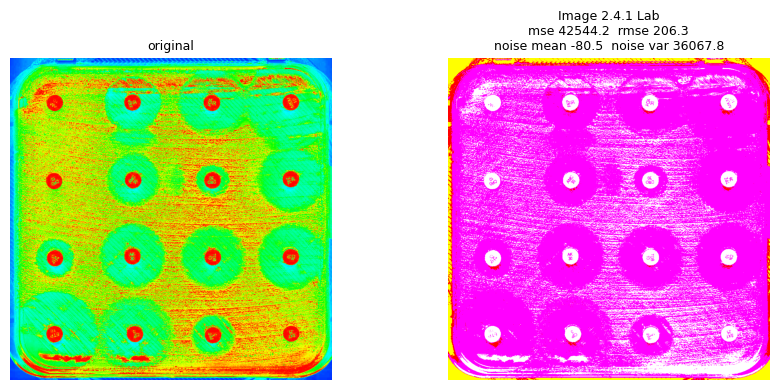

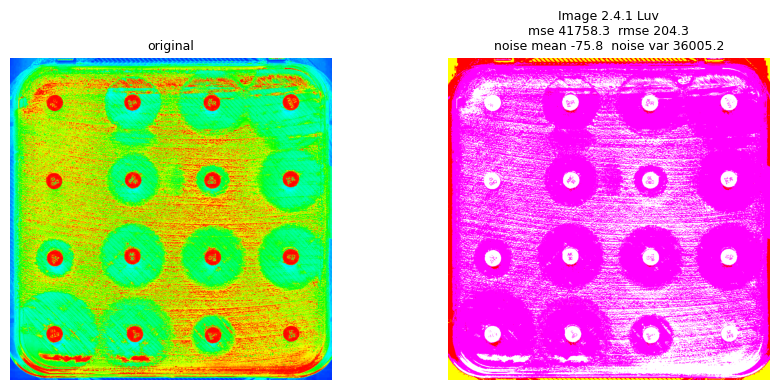

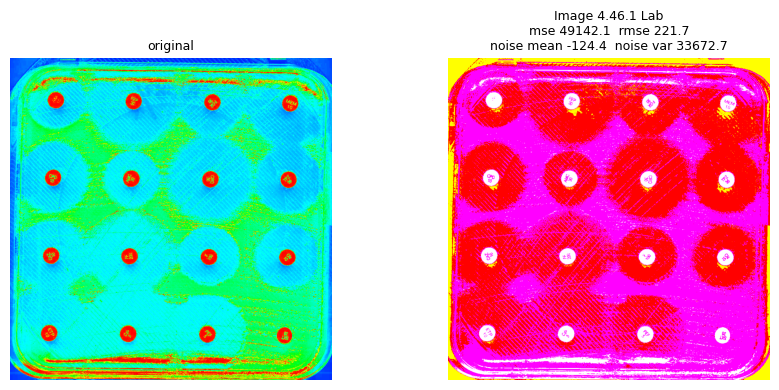

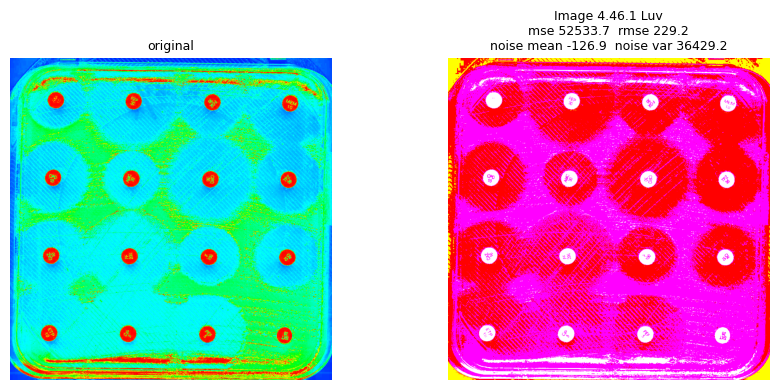

True

In [ ]:
from PIL import Image

cs = ColorSpaces()
rgb241 = cs.gs2rgb(o241)
xyz241 = cs.rgb2xyz(rgb241)
lab241 = cs.xyz2lab(xyz241)
luv241 = cs.xyz2luv(xyz241)
rgb4461 = cs.gs2rgb(o4461)
xyz4461 = cs.rgb2xyz(rgb4461)
lab4461 = cs.xyz2lab(xyz4461)
luv4461 = cs.xyz2luv(xyz4461)
show_result(lab241, rgb241, title="Image 2.4.1 Lab", row=None)
show_result(luv241, rgb241, title="Image 2.4.1 Luv", row=None)
show_result(lab4461, rgb4461, title="Image 4.46.1 Lab", row=None)
show_result(luv4461, rgb4461, title="Image 4.46.1 Luv", row=None)
save_to = "/content/sample_data/"
cv2.imwrite(f"{save_to}/lab241.png", lab241)
cv2.imwrite(f"{save_to}/luv241.png", luv241)
cv2.imwrite(f"{save_to}/lab4462.png", lab4461)
cv2.imwrite(f"{save_to}/luv4462.png", luv4461)
cv2.imwrite(f"{save_to}/rgb241.png", cv2.cvtColor(rgb241, cv2.COLOR_RGB2BGR))



In [ ]:
# statistics
def mse(y_n, y_r):
  """Quantifies distorition in an image"""
  if y_n.shape != y_r.shape:
    raise ValueError(f"{y_n.shape} != {y_r.shape}")
  return np.mean((y_n.astype(np.float64) - y_r.astype(np.float64)) ** 2)

def rmse(y_n, y_r):
  """Model accuracy, smaller (less error) is better"""
  return np.sqrt(mse(y_n, y_r))


In [ ]:
# 5.1 4 Noise functions on 3 images

def uniform(img, mean, variance):
  """Generate Uniform noise"""

  low = mean - np.sqrt(3 * variance)
  high = mean + np.sqrt(3 * variance)
  uniform_noise = np.random.uniform(low, high, img.shape).astype(np.float32)
  noisy_img = img.astype(np.float32) + uniform_noise
  noisy_img = np.rint(np.clip(noisy_img, 0, 255)).astype(np.uint8)
  return noisy_img

def gaussian(img, mean, variance):
  """Generate Gaussian noise"""

  gaussian_noise = np.random.normal(mean, np.sqrt(variance),
                                    img.shape).astype(np.float32)
  noisy_img = img.astype(np.float32) + gaussian_noise
  noisy_img = np.rint(np.clip(noisy_img, 0, 255)).astype(np.uint8)
  return noisy_img

def snp(img, mean, variance):
  """Generate Salt and Pepper noise"""

  p_b = mean / 255
  p_a = np.where(mean != 0,
                 (variance - 255 * mean + 2 * (mean ** 2) - (mean ** 3) / 255) / (mean ** 2),
                 0)
  r = np.random.rand(*img.shape)
  pepper = r < p_a
  salt = r < p_a + p_b
  noisy_img = img.copy()
  noisy_img[pepper] = 0
  noisy_img[salt] = 255
  noisy_img = np.clip(noisy_img, 0, 255).astype(np.uint8)
  return noisy_img

def salt_and_pepper(img, density = 0.2):
  """Generate Salt and Pepper noise"""

  r = np.random.rand(*img.shape)
  pepper = r < density / 2
  salt = r >  1 - density /2
  noisy_img = img.copy()
  noisy_img[pepper] = 0
  noisy_img[salt] = 255
  noisy_img = np.clip(noisy_img, 0, 255).astype(np.uint8)
  return noisy_img

def rayleigh(img, mean, variance):
  """Generate Rayleigh noise"""

  b = 4 * variance / (4 - np.pi)
  a = mean - np.sqrt(np.pi * b / 4)
  scale = np.sqrt(b / 2)
  rayleigh_noise = a + np.random.rayleigh(scale, img.shape).astype(np.float32)
  noisy_img = img.astype(np.float32) + rayleigh_noise
  noisy_img = np.rint(np.clip(noisy_img, 0, 255)).astype(np.uint8)
  return noisy_img

def lognormal(img, mean, variance):
  """Generate lognormal noise"""

  sigma_squared = np.log(1 + variance / mean ** 2)
  sigma = np.sqrt(sigma_squared)
  mu = np.log(mean) - sigma_squared / 2
  lognormal_noise = np.random.lognormal(mu, sigma, img.shape).astype(np.float32)
  noisy_img = img.astype(np.float32) + lognormal_noise
  noisy_img = np.rint(np.clip(noisy_img, 0, 255)).astype(np.uint8)
  return noisy_img


In [ ]:
# 5.2 Estimating noise parameters

from scipy import stats

# Patch
m_o241 = -50
v_o241 = 200

result = rayleigh(o241, m_o241, v_o241)
col = 170
row = 360
size = 50
patch_o241 = o241[row:row+size, col:col+size]
patch_result = result[row:row+size, col:col+size]

def estimate_parameters(orig, noisy, tol = 4):
    noise = noisy.astype(np.float32) - orig.astype(np.float32)
    pixels = noisy.ravel().astype(float)
    plt.figure(figsize = (6, 3.5))
    bins = np.arange(noise.min() - 0.5, noise.max() + 1.5, 1)
    values, edges, _ = plt.hist(noise.ravel(), bins = bins)
    pepper = np.mean(values == 0)
    salt = np.mean(values == 255)
    other = values[(values > 0) & (values < 255)]

    midpoints = (edges[:-1] + edges[1:]) / 2
    mean = np.average(midpoints, weights = values)
    variance = np.average((midpoints - mean) ** 2, weights = values)

    possible_types = []
    if other.size == 0:
        possible_types.append("salt-and-pepper")
    else:
        margin = 3 * other.std() + 3
        if (pepper > 0.002 and other.min() > margin) or (salt > 0.002 and 255 - other.max() > margin):
            possible_types.append("salt-and-pepper")

    skew = stats.skew(values)
    n = pixels.size
    skew, kurt = stats.skew(pixels), stats.kurtosis(pixels)
    se_s, se_k = np.sqrt(6 / n), np.sqrt(24 / n)
    if abs(skew) < tol * se_s:
        if abs(kurt + 1.2) < tol * se_k:
            possible_types.append("uniform")
        if abs(kurt) < tol * se_k:
            possible_types.append("gaussian")
    if abs(skew - 0.63) < tol * se_s and abs(kurt - 0.24) < tol * se_k:
        possible_types.append("rayleigh")

    if not possible_types:
        possible_types.append("unknown")
    return mean, variance, possible_types

In [ ]:
# 5.3 Apply a class of order-statistics(median, max/min/weighted median,
# midpoint, alpha-trimmed mean) filters on generated noisy images

def alpha_trimmed_mean(x, d):
  x = np.sort(x)
  return x[d // 2: len(x) - d // 2].mean()

def midpoint(x):
  return (np.max(x) + np.min(x))/ 2

def weighted_median(x, w):
  """Assume x and w are flat, will error with negative values"""

  half = np.sum(w) / 2.0
  i = np.argsort(x)
  _x = x[i]
  _w = w[i]
  running = np.cumsum(_w)
  for j, v in enumerate(running):
    if v >= half:
      return _x[j]

ORDER_STATISTIC = ("median", "min", "max", "weighted_median", "midpoint",
                   "alpha_trimmed_mean")

def os_filter(img, k, order_statistic, weights=None, d=None):
  if k % 2 == 0:
    raise ValueError("k must be odd")

  if order_statistic not in ORDER_STATISTIC:
    raise ValueError(f"No such order statistic filter called {order_statistic}")
  elif order_statistic in ("median", "min", "max"):
    os_func = getattr(np, order_statistic)
  else:
    os_func = globals()[order_statistic]

  if order_statistic == "weighted_median":
    if weights is None or (k, k) != weights.shape:
      raise ValueError("weighted_median must have k * k weights")
    else:
      weights = weights.flatten()

  if order_statistic == "alpha_trimmed_mean" and \
    (d is None or (d % 2 != 0) or not (0 <= d  < (k ** 2))):
    raise ValueError("alpha_trimmed_mean must have an even d > 0")

  img = img.astype(np.float64)
  size = k // 2
  padded = np.pad(img, size, mode = "reflect")
  out = np.zeros_like(img)

  for i in range(img.shape[0]):
     for j in range(img.shape[1]):
        window = padded[i:i+k, j:j+k]
        flat_window = window.flatten()
        if order_statistic == "weighted_median":
          out[i, j] = os_func(flat_window, weights)
        elif order_statistic == "alpha_trimmed_mean":
          out[i, j] = os_func(flat_window, d)
        else:
          out[i, j] = os_func(flat_window)
  return np.rint(np.clip(out, 0, 255)).astype(np.uint8)


In [ ]:
# 5.4 Adaptive local noise reduction

v = patch_result.var(ddof = 1)

def adaptive_local_noise_reduction(img, var_h, k):
  """var_h: s_h ** 2"""
  if k % 2 == 0:
    raise ValueError("k must be odd")
  if var_h == 0:
    return img
  img = img.astype(np.float64)
  size = k // 2
  padded = np.pad(img, size, mode = "reflect")
  out = np.zeros_like(img)
  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      window = padded[i:i+k,j:j+k]
      m_l = window.mean()
      var_l = window.var(ddof = 1)  # s_l ** 2
      if var_l == var_h:
        out[i,j] = m_l
      elif var_l > var_h:
        out[i,j] = window[k // 2, k // 2] - (var_h / var_l) * (window[k // 2, k // 2] - m_l)
      else:
        out[i,j] = window[k // 2, k // 2] # pick original pixel
  return np.rint(np.clip(out, 0, 255)).astype(np.uint8)

filtered_img = adaptive_local_noise_reduction(result, v, 3)

In [ ]:
# 5.5 Sharpening method using order-statistics (median, max/min/weighted median,
# midpoint, alpha-trimmed mean) filters

def os_filter_any(img, k, order_statistic, weights=None, d=None):
  if img.ndim == 2:
    return os_filter(img, k, order_statistic, weights=weights, d=d)
  return np.stack([os_filter(img[..., c], k, order_statistic, weights=weights, d=d)
                   for c in range(img.shape[2])], axis = -1)

def sharpen(img, k, a, order_statistic, weights=None, d=None):
  img = img.astype(np.float64)
  mask = img - os_filter_any(img, k, order_statistic, weights=weights, d=d)
  return np.rint(np.clip(img + a * mask, 0, 255)).astype(np.uint8)